In [2]:

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))


In [5]:

from src.data_loader import load_raw_data
from src.data_cleaning import clean_data
from src.feature_engineering import create_features
from sklearn.model_selection import train_test_split

# Load and prepare dataset
data = load_raw_data()
data = clean_data(data)
data = create_features(data)

# Separate features and target
X = data.drop(
    columns=["mileage_kmpl", "record_id", "speed_band"],
    errors="ignore"
)

y = data["mileage_kmpl"]

# Recreate the same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Test data loaded successfully!")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Test data loaded successfully!
X_test shape: (9740, 39)
y_test shape: (9740,)


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Load the trained model
model_path = PROJECT_ROOT / "artifacts" / "gradient_boosting_model.joblib"

final_model = joblib.load(model_path)

print("Final model loaded successfully!")


# Generate predictions
y_pred = final_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred

# Create evaluation DataFrame
evaluation_data = pd.DataFrame({
    "Actual Mileage": y_test.values,
    "Predicted Mileage": y_pred,
    "Residual": residuals
})

print("RESIDUAL ANALYSIS")
print("-----------------")

print(evaluation_data.head(10).round(2))

print("\nResidual Statistics")
print(residuals.describe().round(4))


Final model loaded successfully!
RESIDUAL ANALYSIS
-----------------
       Actual Mileage  Predicted Mileage  Residual
8481             9.39               9.14      0.25
37931            7.39               6.89      0.50
16517           30.20              30.46     -0.26
31837           19.98              19.89      0.09
21653           14.90              14.18      0.72
18420           12.20              10.90      1.30
10449           23.32              23.76     -0.44
14792           29.63              29.36      0.27
28854           27.96              28.02     -0.06
34071           16.46              17.01     -0.55

Residual Statistics
count    9740.0000
mean       -0.0144
std         2.0626
min       -15.6393
25%        -1.0881
50%        -0.0370
75%         1.0146
max        11.8910
Name: mileage_kmpl, dtype: float64


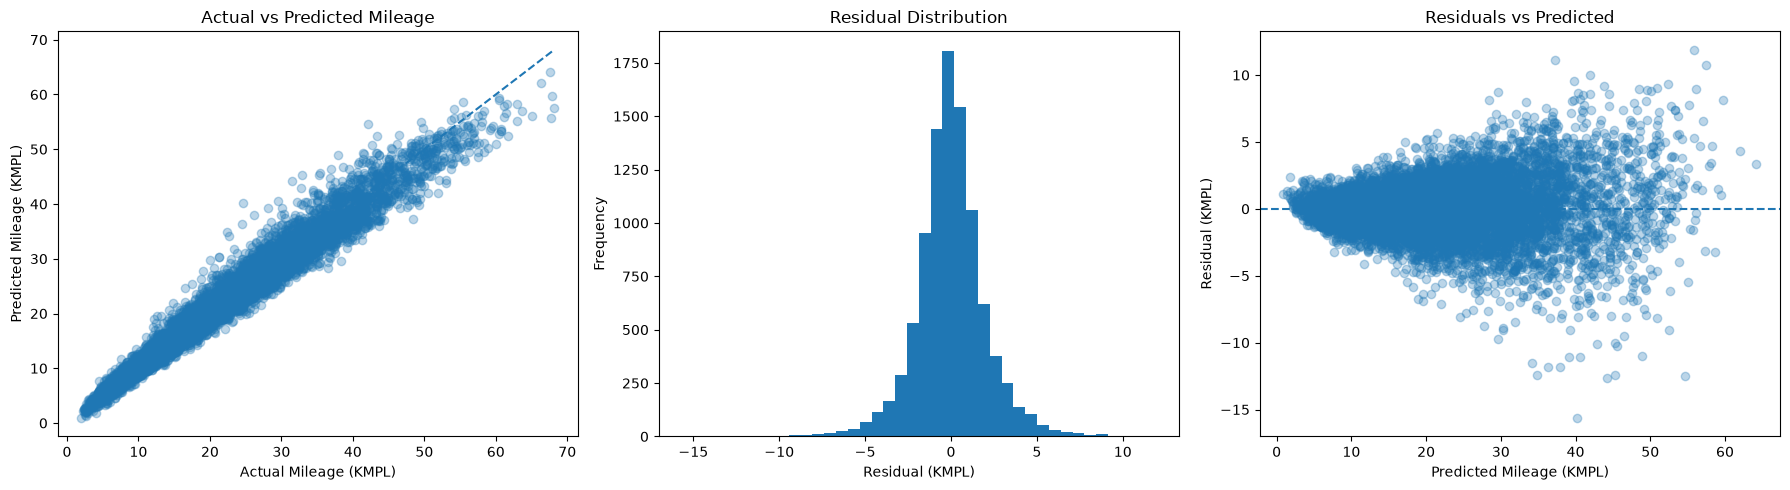

In [7]:

# Create three diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.3)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
axes[0].set_title("Actual vs Predicted Mileage")
axes[0].set_xlabel("Actual Mileage (KMPL)")
axes[0].set_ylabel("Predicted Mileage (KMPL)")

# 2. Residual Distribution
axes[1].hist(residuals, bins=40)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual (KMPL)")
axes[1].set_ylabel("Frequency")

# 3. Residuals vs Predicted
axes[2].scatter(y_pred, residuals, alpha=0.3)
axes[2].axhline(y=0, linestyle="--")
axes[2].set_title("Residuals vs Predicted")
axes[2].set_xlabel("Predicted Mileage (KMPL)")
axes[2].set_ylabel("Residual (KMPL)")

plt.tight_layout()
plt.show()


DIAGNOSTIC CHECKS
-----------------
Actual vs Predicted Correlation: 0.9825
Mean Residual: -0.0144
Residual Standard Deviation: 2.0626

Predictions within 1 KMPL: 48.20%
Predictions within 2 KMPL: 75.34%
Predictions within 3 KMPL: 87.97%

Predictions with error above 5 KMPL: 294
Percentage of large errors: 3.02%
